<a href="https://colab.research.google.com/github/Ansarss/Ai_learning_experiments/blob/main/Construction_Injury_Risk_RF_Bayesian_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Construction Industry Injury Risk Prediction Using Random Forest, Bayesian Optimization, and Bayesian Updating

**Student:** Ansar Shigganvi  
**Course:** Analytical Methods for Machine Learning (PhDAI-731-M81)  
**Institution:** University of the Cumberlands  
**Program:** Executive Ph.D. in Artificial Intelligence  
**Date:** November 21, 2026

## Research Overview

This project investigates the application of Random Forest classification, Bayesian Optimization, and Bayesian inference to predict occupational injury and illness risk in the United States construction industry. The analysis uses publicly available OSHA Injury Tracking Application (ITA) Form 300A summary data from 2023 and 2024.

The study evaluates whether historical establishment characteristics and injury records can predict the likelihood of an OSHA-recordable workplace injury or illness in the subsequent year.

## Rationale for Dataset Selection

I selected the construction industry because of my professional experience in construction technology and project management. Construction safety is an important industry challenge, and predicting occupational injury risk presents an opportunity to explore how machine learning and probabilistic methods can support proactive risk assessment.

Unlike the medical diagnosis example, this study applies similar analytical techniques to construction establishments, using historical safety records and establishment characteristics to estimate the likelihood of reported workplace injuries or illnesses.

The objective is to compare Random Forest models with Bayesian approaches, evaluate Bayesian hyperparameter optimization, and investigate how historical information can inform updated risk estimates.

## Dataset and Research Question

**Data Source:** U.S. Occupational Safety and Health Administration (OSHA), Injury Tracking Application (ITA), Form 300A Summary Data for 2023 and 2024.

**Population:** U.S. construction establishments classified under NAICS sector 23, specifically:

- **236:** Construction of Buildings
- **237:** Heavy and Civil Engineering Construction
- **238:** Specialty Trade Contractors

**Research Question:** Among construction establishments appearing in both years, can 2023 establishment characteristics and injury history predict whether an establishment reports at least one OSHA-recordable injury or illness in 2024?

## Methodological Approach

The research evaluates three complementary approaches:

1. **Random Forest Classification:** Develop a baseline machine learning model using 2023 establishment characteristics and historical injury records to predict 2024 injury or illness reporting outcomes.

2. **Bayesian Optimization:** Apply Optuna's Tree-structured Parzen Estimator (TPE) algorithm to optimize Random Forest hyperparameters using cross-validation.

3. **Bayesian Updating:** Implement an empirical-Bayes Beta-Binomial model that uses historical 2023 injury reporting rates to establish prior probability distributions and updates these distributions using 2024 training observations.

Models are evaluated using held-out test data and performance metrics including accuracy, precision, recall, F1-score, ROC-AUC, PR-AUC, Brier score, and log loss.

## Interpretation and Limitations

- **Unit of Analysis:** Each observation represents one reporting construction establishment, not an individual worker or construction project.

- **Target Variable:** `target_2024` indicates whether an establishment reported at least one OSHA-recordable injury or illness in 2024. The original OSHA field, `no_injuries_illnesses`, uses `1` for establishments with reported injuries or illnesses and `2` for establishments without them.

- **Data Leakage Prevention:** Predictive features are derived exclusively from 2023 data. The 2024 outcome is reserved for supervised model training and evaluation.

- **Establishment Matching:** Establishments are linked between reporting years using establishment identifiers, with additional checks for consistency in state and NAICS three-digit subsector. Potential matching errors remain a limitation.

- **Population Representativeness:** The dataset includes establishments reporting through OSHA's ITA system and is not a complete or representative census of all U.S. construction establishments.

- **Bayesian Priors:** Historical injury reporting rates provide empirical prior information but do not establish causal relationships between establishment characteristics and workplace safety outcomes.

- **Bayesian Method Distinction:** Bayesian Optimization tunes Random Forest hyperparameters, whereas Bayesian inference updates probability distributions as additional evidence becomes available.

- **MCMC Diagnostics:** PyMC and Markov Chain Monte Carlo sampling are used to examine posterior distributions and sampling convergence. Convergence does not independently validate predictive accuracy.

- **Practical Limitations:** Model predictions represent estimated reporting probabilities and should not independently determine workplace safety or regulatory decisions.

## Official References

- [OSHA ITA Data Downloads](https://www.osha.gov/itadata)
- [OSHA Form 300A Summary Data Dictionary](https://www.osha.gov/sites/default/files/summary_data_dictionary.pdf)
- [OSHA ITA Data User's Guide](https://www.osha.gov/sites/default/files/ITA_data_users_guide.pdf)
- [U.S. Census Bureau NAICS Classification](https://www.census.gov/naics/)
- [Optuna TPESampler Documentation](https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html)
- [PyMC Beta Distribution Documentation](https://www.pymc.io/projects/docs/en/stable/api/distributions/generated/pymc.Beta.html)

In [1]:
%pip -q install -U "optuna>=4,<6" "pymc>=5.20,<6" "arviz>=0.19,<0.23"

In [2]:
import io, re, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import scipy.stats as st
from pathlib import Path
from IPython.display import display

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss, log_loss,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay,
)
import optuna

SEED = 42
MAX_MATCHED_ROWS = 30000   # None = use every matched establishment
N_OPTUNA_TRIALS = 12       # Increase to 25+ for a deeper search
RUN_PYMC_TRACE = True      # Set False for faster execution
PRIOR_EFFECTIVE_N = 30.0  # Prior pseudo-observations per NAICS3 + 2023 size cohort
np.random.seed(SEED)
sns.set_theme(style='whitegrid')
print('Pandas:', pd.__version__, '| Optuna:', optuna.__version__)

Pandas: 2.2.3 | Optuna: 5.1.0


## 2. Load the OSHA 2023 and 2024 establishment-level files


In [3]:
OSHA_FILES = {
  2023: 'https://www.osha.gov/sites/default/files/ITA_300A_Summary_Data_2023_through_12-31-2024.zip',
  2024: 'https://www.osha.gov/sites/default/files/ITA_300A_Summary_Data_2024_through_12-31-2025.zip',
}
DATA_MODE = 'upload'   # Change to 'upload' when automatic download is blocked

def read_annual_summary(payload: bytes, source_name: str) -> pd.DataFrame:
    """Read an OSHA ZIP (with a CSV inside) or an uncompressed CSV."""
    buffer = io.BytesIO(payload)
    if zipfile.is_zipfile(buffer):
        with zipfile.ZipFile(buffer) as archive:
            candidates = [p for p in archive.namelist() if p.lower().endswith('.csv') and not p.startswith('__MACOSX')]
            if not candidates:
                raise ValueError(f'{source_name}: no CSV inside ZIP')
            filename = max(candidates, key=lambda name: archive.getinfo(name).file_size)
            with archive.open(filename) as stream:
                df = pd.read_csv(stream, low_memory=False, encoding='utf-8-sig', encoding_errors='replace')
            print(f'{source_name} -> {filename}: {len(df):,} rows, {len(df.columns)} columns')
            return df
    df = pd.read_csv(buffer, low_memory=False, encoding='utf-8-sig', encoding_errors='replace')
    print(f'{source_name}: {len(df):,} rows, {len(df.columns)} columns')
    return df

if DATA_MODE == 'auto':
    raw = {}
    for year, url in OSHA_FILES.items():
        try:
            r = requests.get(url, headers={'User-Agent': 'Mozilla/5.0 (academic research)'}, timeout=180)
            r.raise_for_status()
            raw[year] = read_annual_summary(r.content, f'OSHA {year}')
        except Exception as exc:
            raise RuntimeError(
                f'Unable to download OSHA {year} automatically: {exc}. '
                'Download the two annual Summary Data ZIP files from https://www.osha.gov/itadata; '
                'set DATA_MODE = "upload" and rerun this cell.'
            ) from exc
elif DATA_MODE == 'upload':
    from google.colab import files
    print('Please upload exactly the 2023 and 2024 OSHA Summary Data ZIP files (or extracted CSVs).')
    uploads = files.upload()
    raw = {}
    for year in (2023, 2024):
        matching = [
    name for name in uploads
    if name.startswith(f'ITA_300A_Summary_Data_{year}_')
    and name.lower().endswith(('.csv', '.zip'))
]
        if len(matching) != 1:
            raise ValueError(f'Could not identify exactly one uploaded file for {year}. Files: {list(uploads)}')
        raw[year] = read_annual_summary(uploads[matching[0]], matching[0])
else:
    raise ValueError('DATA_MODE must be "auto" or "upload".')

for year in (2023, 2024):
    print(f'\n{year} column names:')
    print(raw[year].columns.tolist())

Please upload exactly the 2023 and 2024 OSHA Summary Data ZIP files (or extracted CSVs).


Saving ITA_300A_Summary_Data_2023_through_12-31-2024.zip to ITA_300A_Summary_Data_2023_through_12-31-2024.zip
Saving ITA_300A_Summary_Data_2024_through_12-31-2025.zip to ITA_300A_Summary_Data_2024_through_12-31-2025.zip
ITA_300A_Summary_Data_2023_through_12-31-2024.zip -> ITA 300A Summary Data 2023 through 12-31-2024_v2.csv: 394,234 rows, 32 columns
ITA_300A_Summary_Data_2024_through_12-31-2025.zip -> ITA_300A_Summary_Data_2024_through_12-31-2025_v2.csv: 398,620 rows, 32 columns

2023 column names:
['id', 'establishment_name', 'establishment_id', 'ein', 'company_name', 'street_address', 'city', 'state', 'zip_code', 'naics_code', 'naics_year', 'industry_description', 'establishment_type', 'size', 'annual_average_employees', 'total_hours_worked', 'no_injuries_illnesses', 'total_deaths', 'total_dafw_cases', 'total_djtr_cases', 'total_other_cases', 'total_dafw_days', 'total_djtr_days', 'total_injuries', 'total_skin_disorders', 'total_respiratory_conditions', 'total_poisonings', 'total_hear

## 3. Clean, filter construction (NAICS 23), and validate the year-over-year match

OSHA Form 300A's official dictionary says `no_injuries_illnesses`: **1 = at least one recordable injury or illness; 2 = none**. We do **not** reverse this label. We use the employer's **2023** report as input and the **2024** report as the outcome.

**Data-quality safeguards:** missing IDs/invalid NAICS/invalid labels are excluded; duplicate establishment IDs are deduplicated; records must agree on state and NAICS 3-digit construction subsector. Match counts and exclusions are printed so the reader can assess selection bias.

In [4]:
def prep_year(df: pd.DataFrame, year: int) -> pd.DataFrame:
    x = df.copy()
    x.columns = [str(c).strip().lower() for c in x.columns]
    required = ['establishment_id','naics_code','state','no_injuries_illnesses',
                'size','annual_average_employees','total_hours_worked']
    missing = sorted(set(required) - set(x.columns))
    if missing:
        raise ValueError(f'{year} OSHA file is missing required columns: {missing}. Check that you uploaded Form 300A Summary Data.')

    # Convert numeric codes using nullable integers, preserving missing values.
    naics_numeric = pd.to_numeric(x['naics_code'], errors='coerce').astype('Int64')
    x['naics6'] = naics_numeric.astype(str).replace('<NA>', pd.NA).str.zfill(6)
    x = x[x['naics6'].str.fullmatch(r'23[678]\d{3}', na=False)].copy()
    x['naics3'] = x['naics6'].str[:3]
    x['naics4'] = x['naics6'].str[:4]

    x['establishment_id'] = pd.to_numeric(x['establishment_id'], errors='coerce').astype('Int64')
    x['no_injuries_illnesses'] = pd.to_numeric(x['no_injuries_illnesses'], errors='coerce')
    x = x[x['establishment_id'].notna() & x['no_injuries_illnesses'].isin([1, 2])].copy()
    x['reported_case'] = (x['no_injuries_illnesses'] == 1).astype('int8')
    x['state'] = x['state'].astype('string').str.upper().str.strip()
    x = x[x['state'].str.fullmatch('[A-Z]{2}', na=False)].copy()

    for col in ('size','annual_average_employees','total_hours_worked',
                'total_dafw_cases','total_djtr_cases','total_other_cases'):
        if col not in x: x[col] = np.nan
        x[col] = pd.to_numeric(x[col], errors='coerce')
    x['size'] = x['size'].astype('Int64').astype(str).replace('<NA>', 'unknown')
    x.loc[x['annual_average_employees'] < 0, 'annual_average_employees'] = np.nan
    x.loc[x['total_hours_worked'] <= 0, 'total_hours_worked'] = np.nan
    x['prior_total_cases'] = x[['total_dafw_cases','total_djtr_cases','total_other_cases']].sum(axis=1, min_count=1)
    # Historical incidence rate per 100 equivalent full-time employees, not a 2024 feature.
    x['prior_tcr'] = x['prior_total_cases'] * 200000 / x['total_hours_worked']
    x['prior_tcr'] = x['prior_tcr'].replace([np.inf,-np.inf], np.nan).clip(lower=0, upper=100)
    x['cohort'] = x['naics3'] + '|' + x['size']

    if 'created_timestamp' in x.columns:
        x['_submission_sort'] = pd.to_datetime(x['created_timestamp'], errors='coerce', utc=True)
        # Some historical files store timestamps as epoch values; sort is only for deduplication.
        if x['_submission_sort'].isna().all():
            x['_submission_sort'] = x['created_timestamp'].astype(str)
        x = x.sort_values('_submission_sort', kind='stable')
    dupes = x['establishment_id'].duplicated().sum()
    x = x.drop_duplicates('establishment_id', keep='last').copy()
    print(f'{year}: {len(x):,} eligible construction establishments; {dupes:,} duplicate ID rows removed; '
          f'reported-case rate={x.reported_case.mean():.1%}')
    return x

x23 = prep_year(raw[2023], 2023)
x24 = prep_year(raw[2024], 2024)

keep23 = ['establishment_id','establishment_name','company_name','state','naics3','naics4',
          'size','annual_average_employees','total_hours_worked','reported_case',
          'prior_total_cases','prior_tcr','cohort']
for optional in ['establishment_name','company_name']:
    if optional not in x23.columns: x23[optional] = ''

joined_unchecked = x23[keep23].merge(
    x24[['establishment_id','establishment_name','state','naics3','reported_case']],
    on='establishment_id', how='inner', suffixes=('_2023','_2024'),
    validate='one_to_one'
)
match_ok = ((joined_unchecked['state_2023'] == joined_unchecked['state_2024']) &
            (joined_unchecked['naics3_2023'] == joined_unchecked['naics3_2024']))
matched = joined_unchecked[match_ok].copy()
matched = matched.rename(columns={'reported_case_2024': 'target_2024'})

print(f'\n2023 establishments found by ID in 2024: {len(joined_unchecked):,}')
print(f'Rejected due to state or NAICS3 mismatch: {(~match_ok).sum():,}')
print(f'Retained plausible historical matches: {len(matched):,}')
if 'establishment_name_2024' in matched.columns:
    clean_name = lambda s: s.fillna('').astype(str).str.lower().str.replace(r'[^a-z0-9]', '', regex=True)
    same_name = (clean_name(matched['establishment_name_2023']) == clean_name(matched['establishment_name_2024']))
    print(f'Matched ID records with identical normalized establishment names: {same_name.mean():.1%}')
    print('Name mismatches may reflect spelling changes, business renaming, or matching problems; review them.')
print(f'2024 target prevalence within matched cohort: {matched.target_2024.mean():.2%}')
if len(matched) < 500 or matched['target_2024'].nunique() != 2:
    raise ValueError('Not enough usable 2023→2024 matched establishments for binary classification. '
                     'Review the dataset versions and ID-matching diagnostics; do not silently fall back to same-year predictors.')
if MAX_MATCHED_ROWS is not None and len(matched) > MAX_MATCHED_ROWS:
    matched = matched.sample(n=MAX_MATCHED_ROWS, random_state=SEED).reset_index(drop=True)
    print(f'Sampled {len(matched):,} matched establishments for Colab performance.')

# Remove identifying text from model input. Keep company name only to group train/test split.
display(matched[['establishment_id','state_2023','naics3_2023','size',
                 'reported_case_2023','target_2024']].head())

2023: 39,900 eligible construction establishments; 0 duplicate ID rows removed; reported-case rate=54.6%
2024: 39,134 eligible construction establishments; 0 duplicate ID rows removed; reported-case rate=52.3%

2023 establishments found by ID in 2024: 23,764
Rejected due to state or NAICS3 mismatch: 104
Retained plausible historical matches: 23,660
Matched ID records with identical normalized establishment names: 97.9%
Name mismatches may reflect spelling changes, business renaming, or matching problems; review them.
2024 target prevalence within matched cohort: 56.72%


,establishment_id,state_2023,naics3_2023,size,reported_case_2023,target_2024
0,541252,OH,238,2,0,0
1,410001,NE,238,1,0,0
2,897617,GU,236,2,1,1
3,74423,NY,238,1,0,0
4,74416,NY,238,1,1,1


## 4. Exploratory analysis (descriptive, not causal)

Check historical 2023→2024 transitions, class imbalance, and differences across the three construction subsectors. These plots describe the retained matched cohort only, not all U.S. construction employers.

Matched 2023→2024 injury/illness reporting transitions:


Reported any case 2024,0,1,All
Reported any case 2023,,,
0,6933,3090,10023
1,3307,10330,13637
All,10240,13420,23660


,2024 event share,establishments
naics3_2023,,
236,0.480849,5091
237,0.592069,5094
238,0.590427,13475


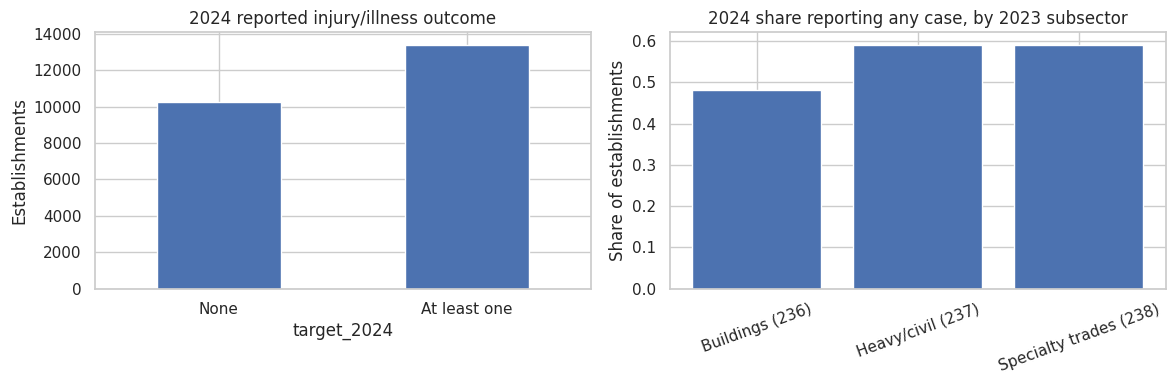

In [5]:
print('Matched 2023→2024 injury/illness reporting transitions:')
display(pd.crosstab(matched['reported_case_2023'], matched['target_2024'],
                    rownames=['Reported any case 2023'], colnames=['Reported any case 2024'], margins=True))

by_subsector = (matched.groupby('naics3_2023', observed=True)['target_2024']
                 .agg(['mean','size']).rename(columns={'mean':'2024 event share','size':'establishments'}))
display(by_subsector)
labels = {'236':'Buildings (236)', '237':'Heavy/civil (237)', '238':'Specialty trades (238)'}
fig, axs = plt.subplots(1, 2, figsize=(12,4))
matched['target_2024'].value_counts().sort_index().rename(index={0:'None',1:'At least one'}).plot.bar(ax=axs[0], title='2024 reported injury/illness outcome')
axs[0].set_ylabel('Establishments'); axs[0].tick_params(axis='x', rotation=0)
axs[1].bar([labels.get(x,x) for x in by_subsector.index], by_subsector['2024 event share'])
axs[1].set_title('2024 share reporting any case, by 2023 subsector')
axs[1].set_ylabel('Share of establishments'); axs[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

## 5. Group-aware train/test split and leakage-safe features

Use **only 2023 variables**. Names and IDs are excluded as predictors. We split by employer name (or establishment ID if missing) to reduce the risk of having the same employer in both train and test. Hyperparameter tuning is performed using group-aware cross-validation **inside the training set only**.

In [6]:
num_features = [
    'annual_average_employees', 'total_hours_worked', 'reported_case_2023',
    'prior_total_cases', 'prior_tcr'
]
cat_features = ['state_2023','naics3_2023','naics4','size']
feature_cols = num_features + cat_features

# Company grouping: approximate protection against repeat-employer leakage.
company_group = matched['company_name'].fillna('').astype(str).str.lower().str.replace(r'[^a-z0-9]', '', regex=True)
company_group = company_group.where(company_group.str.len().ge(4), 'est_'+matched['establishment_id'].astype(str))
matched['company_group'] = company_group
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(splitter.split(matched, matched.target_2024, groups=matched.company_group))
train_df = matched.iloc[train_idx].reset_index(drop=True)
test_df = matched.iloc[test_idx].reset_index(drop=True)
X_train, y_train = train_df[feature_cols], train_df.target_2024.astype(int)
X_test, y_test = test_df[feature_cols], test_df.target_2024.astype(int)
groups_train = train_df.company_group

assert set(train_df.company_group).isdisjoint(set(test_df.company_group)), 'Company leakage in train/test split'
assert set(X_train.columns).isdisjoint(set(x24.columns) - set(x23.columns)), 'Unexpected feature name'
if y_train.nunique() != 2 or y_test.nunique() != 2:
    raise ValueError('Train/test split contains only one label. Try another SEED.')

print('Training rows:', len(train_df), 'positive class:', round(y_train.mean(),3))
print('Test rows:', len(test_df), 'positive class:', round(y_test.mean(),3))
print('Train employers:', train_df.company_group.nunique(), '| test employers:', test_df.company_group.nunique())

preprocess = ColumnTransformer([
    ('numeric', SimpleImputer(strategy='median', add_indicator=True), num_features),
    ('categorical', Pipeline([
        ('fill', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_features),
], remainder='drop')

cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)

Training rows: 18659 positive class: 0.571
Test rows: 5001 positive class: 0.553
Train employers: 14280 | test employers: 3571


## 6. Baseline Random Forest

A Random Forest is a supervised ensemble of decision trees. This baseline trains on the 2024 outcomes of **training establishments** using only 2023 features. We reserve the 2024 test outcomes for final evaluation.

In [7]:
base_rf = Pipeline([
    ('features', preprocess),
    ('model', RandomForestClassifier(
        n_estimators=150, max_depth=14, min_samples_leaf=3,
        class_weight='balanced_subsample', n_jobs=-1, random_state=SEED
    ))
])
base_rf.fit(X_train, y_train)
rf_baseline_probs = base_rf.predict_proba(X_test)[:,1]
print('Baseline Random Forest fitted.')

Baseline Random Forest fitted.


## 7. Bayesian **hyperparameter optimization** with Optuna (TPE)

Optuna's Tree-structured Parzen Estimator (TPE) uses previous trial outcomes to choose promising parameter values. The objective is **3-fold group-aware ROC-AUC on the training set**. We do not optimize using the test set.

  0%|          | 0/12 [00:00<?, ?it/s]

Best cross-validated ROC-AUC: 0.81
Chosen RF parameters: {'n_estimators': 180, 'max_depth': 19, 'min_samples_leaf': 10, 'min_samples_split': 14, 'max_features': 'sqrt'}


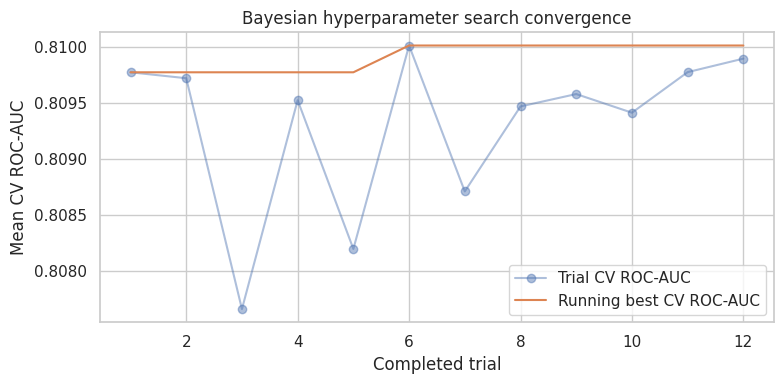

In [8]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    rf = RandomForestClassifier(
        n_estimators=trial.suggest_int('n_estimators', 80, 300, step=20),
        max_depth=trial.suggest_int('max_depth', 5, 22),
        min_samples_leaf=trial.suggest_int('min_samples_leaf', 1, 12),
        min_samples_split=trial.suggest_int('min_samples_split', 2, 15),
        max_features=trial.suggest_categorical('max_features', ['sqrt','log2',0.7]),
        class_weight='balanced_subsample', n_jobs=-1, random_state=SEED
    )
    pipe = Pipeline([('features', preprocess), ('model', rf)])
    cv_scores = cross_val_score(pipe, X_train, y_train, groups=groups_train,
                                cv=cv, scoring='roc_auc', n_jobs=1, error_score='raise')
    return float(cv_scores.mean())

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=5))
study.optimize(objective, n_trials=N_OPTUNA_TRIALS, show_progress_bar=True)
print('Best cross-validated ROC-AUC:', round(study.best_value, 4))
print('Chosen RF parameters:', study.best_params)

# Optuna convergence: running best *training cross-validation* score, NOT test score.
trial_scores = [t.value for t in study.trials if t.value is not None]
plt.figure(figsize=(8,4))
plt.plot(range(1, len(trial_scores)+1), trial_scores, marker='o', alpha=.45, label='Trial CV ROC-AUC')
plt.plot(range(1, len(trial_scores)+1), np.maximum.accumulate(trial_scores), label='Running best CV ROC-AUC')
plt.xlabel('Completed trial'); plt.ylabel('Mean CV ROC-AUC'); plt.title('Bayesian hyperparameter search convergence')
plt.legend(); plt.tight_layout(); plt.show()

In [9]:
optimized_rf = Pipeline([
    ('features', preprocess),
    ('model', RandomForestClassifier(
        **study.best_params,
        class_weight='balanced_subsample', n_jobs=-1, random_state=SEED
    ))
])
optimized_rf.fit(X_train, y_train)
rf_optimized_probs = optimized_rf.predict_proba(X_test)[:,1]
print('Optimized Random Forest fitted.')

Optimized Random Forest fitted.


## 8. Bayesian updating: historical prior --> posterior probability

A separate Bayesian estimator uses **2023 construction-sector group event shares** as empirical prior knowledge about whether a reporting establishment records at least one injury/illness. Each group is defined by **2023 NAICS3 subsector + 2023 OSHA size category**. The update adds only **2024 training labels**. Test labels remain untouched.

For group \(g\):

\[
\theta_g \sim \mathrm{Beta}(\alpha_{0g},\beta_{0g})
\quad ;\quad S_g\mid\theta_g\sim\mathrm{Binomial}(N_g,\theta_g)
\]
\[
\theta_g\mid S_g,N_g \sim \mathrm{Beta}(\alpha_{0g}+S_g,\;\beta_{0g}+N_g-S_g)
\]

We smooth the historical 2023 group rate toward the overall 2023 construction rate, then use it as the prior center. `PRIOR_EFFECTIVE_N` controls how strongly the 2023 evidence is carried into 2024. Posterior means become **group-level** probabilities for held-out establishments. This is a **genuine probability update**, not merely a renamed Random Forest prediction.

**Critical:** Because priors are *empirically estimated* from 2023 rather than stipulated from a fully specified joint generative model, this is an **empirical-Bayes Beta-Binomial** approximation; credible intervals are conditional on estimated hyperparameters. The group model is simpler than RF and may not be more accurate.

2023 overall construction reported-case share: 54.6%
Cohorts in posterior: 15


,cohort,n23,n24_train,prior_mean,posterior_mean,ci_low,ci_high
11,238|2,8439,4554,0.593534,0.606409,0.592228,0.620503
12,238|21,8492,3388,0.550553,0.572403,0.555785,0.588940
1,236|2,4036,2153,0.511691,0.515503,0.494542,0.536438
6,237|2,3619,1992,0.613657,0.635690,0.614606,0.656521
10,238|1,2966,1077,0.249703,0.276817,0.250884,0.303513
7,237|21,1865,847,0.482979,0.506775,0.473736,0.539785
2,236|21,2056,839,0.433956,0.443039,0.410200,0.476125
13,238|22,1950,797,0.779077,0.816563,0.789524,0.842155
9,237|3,1230,708,0.650043,0.675407,0.641258,0.708659
14,238|3,1330,667,0.876719,0.884199,0.859478,0.906838


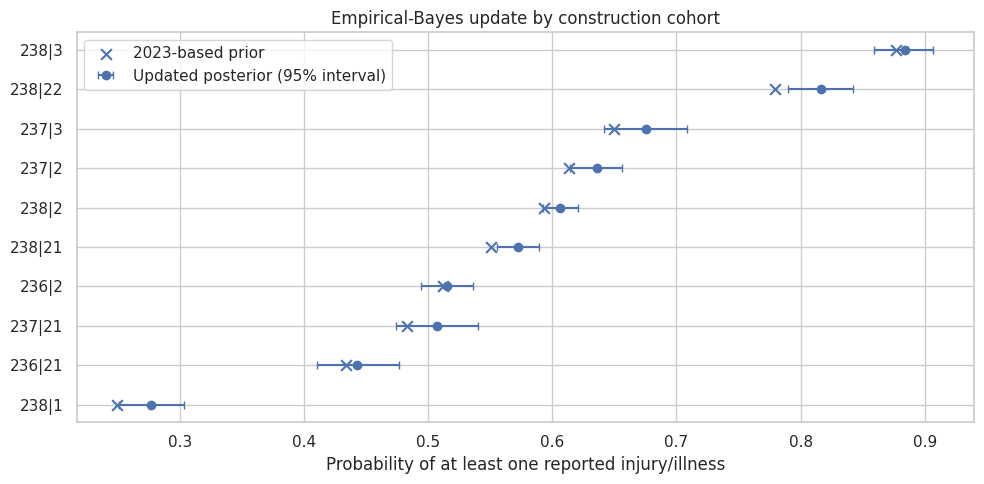

In [10]:
# Historical empirical priors from 2023 (valid for training and test firms because 2023 precedes 2024).
historical = x23[['cohort','reported_case']].copy()
global_2023_rate = historical.reported_case.mean()
h23 = historical.groupby('cohort').reported_case.agg(n23='size', s23='sum').reset_index()
SMOOTHING = 10.0
h23['historical_rate'] = (h23.s23 + SMOOTHING * global_2023_rate) / (h23.n23 + SMOOTHING)
h23['alpha0'] = 1 + PRIOR_EFFECTIVE_N * h23.historical_rate
h23['beta0'] = 1 + PRIOR_EFFECTIVE_N * (1 - h23.historical_rate)

# 2024 training outcomes are used to update priors. Never include y_test here.
train_counts = train_df.groupby('cohort').target_2024.agg(n24_train='size', s24_train='sum').reset_index()
post = h23.merge(train_counts, on='cohort', how='left')
post[['n24_train','s24_train']] = post[['n24_train','s24_train']].fillna(0)
post['alpha_post'] = post.alpha0 + post.s24_train
post['beta_post'] = post.beta0 + post.n24_train - post.s24_train
post['prior_mean'] = post.alpha0 / (post.alpha0 + post.beta0)
post['posterior_mean'] = post.alpha_post / (post.alpha_post + post.beta_post)
post['ci_low'] = st.beta.ppf(0.025, post.alpha_post, post.beta_post)
post['ci_high'] = st.beta.ppf(0.975, post.alpha_post, post.beta_post)

# Fallback for a cohort not seen in 2023: smoothed overall historical rate.
global_a0 = 1 + PRIOR_EFFECTIVE_N * global_2023_rate
global_b0 = 1 + PRIOR_EFFECTIVE_N * (1-global_2023_rate)
prior_map = post.set_index('cohort').prior_mean.to_dict()
post_map = post.set_index('cohort').posterior_mean.to_dict()
bayes_prior_probs = test_df.cohort.map(prior_map).fillna(global_a0/(global_a0+global_b0)).to_numpy()
bayes_posterior_probs = test_df.cohort.map(post_map).fillna(global_a0/(global_a0+global_b0)).to_numpy()

print('2023 overall construction reported-case share:', f'{global_2023_rate:.1%}')
print('Cohorts in posterior:', len(post))
display(post[['cohort','n23','n24_train','prior_mean','posterior_mean','ci_low','ci_high']]
        .sort_values('n24_train', ascending=False).head(12))

# Visualize how learned group probabilities move with training evidence.
plot_post = post.sort_values('n24_train',ascending=False).head(10).sort_values('posterior_mean')
fig, ax = plt.subplots(figsize=(10,5))
ypos = np.arange(len(plot_post))
ax.scatter(plot_post.prior_mean, ypos, label='2023-based prior', marker='x', s=60)
ax.errorbar(plot_post.posterior_mean, ypos,
            xerr=[plot_post.posterior_mean-plot_post.ci_low, plot_post.ci_high-plot_post.posterior_mean],
            fmt='o', capsize=3, label='Updated posterior (95% interval)')
ax.set_yticks(ypos, plot_post.cohort)
ax.set_xlabel('Probability of at least one reported injury/illness'); ax.set_title('Empirical-Bayes update by construction cohort')
ax.legend(); plt.tight_layout(); plt.show()

### Illustration: how the posterior changes as training outcomes accumulate

This is a **randomized illustrative order** of 2024 training establishments within one cohort. It is not a timestamped stream and should not be described as a real-time longitudinal updating experiment.

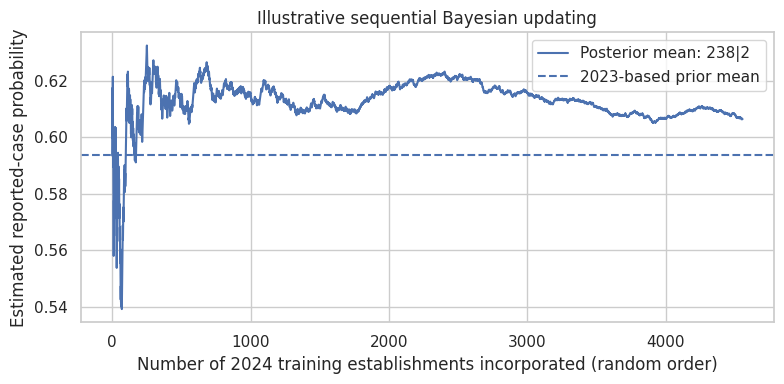

In [11]:
if len(train_counts) > 0:
    most_common = train_counts.sort_values('n24_train', ascending=False).iloc[0]['cohort']
    p = post.set_index('cohort').loc[most_common]
    events = train_df.loc[train_df.cohort.eq(most_common), 'target_2024'].to_numpy()
    events = np.random.default_rng(SEED).permutation(events)
    cumulative = np.arange(len(events)+1)
    successes = np.r_[0, events.cumsum()]
    posterior_trajectory = (p.alpha0+successes)/(p.alpha0+p.beta0+cumulative)
    plt.figure(figsize=(8,4))
    plt.plot(cumulative,posterior_trajectory, label=f'Posterior mean: {most_common}')
    plt.axhline(p.prior_mean,ls='--',label='2023-based prior mean')
    plt.xlabel('Number of 2024 training establishments incorporated (random order)')
    plt.ylabel('Estimated reported-case probability')
    plt.title('Illustrative sequential Bayesian updating')
    plt.legend();plt.tight_layout();plt.show()

## 9. Out-of-sample model comparison

Compare four predictions for the **same untouched 2024 test establishments**: (a) baseline RF, (b) RF tuned with TPE, (c) 2023 historical prior only, and (d) posterior after learning from 2024 **training** outcomes.

Metrics: Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC, Brier score, and Log Loss. A **lower** Brier score or log loss is better. The classification threshold is fixed at 0.5 for fairness; a different threshold would have to be chosen using **training** validation data, never the test data.

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier (lower better),Log Loss (lower better)
Model,,,,,,,,
Random Forest baseline,0.7293,0.7873,0.6997,0.7409,0.8034,0.8412,0.1811,0.5365
Random Forest optimized (Optuna TPE),0.7297,0.7884,0.6990,0.7410,0.8024,0.8414,0.1815,0.5380
Bayesian 2023 prior only,0.6181,0.6045,0.8959,0.7219,0.6544,0.6772,0.2271,0.6452
Bayesian 2024 posterior,0.6169,0.6003,0.9205,0.7267,0.6544,0.6769,0.2275,0.6461


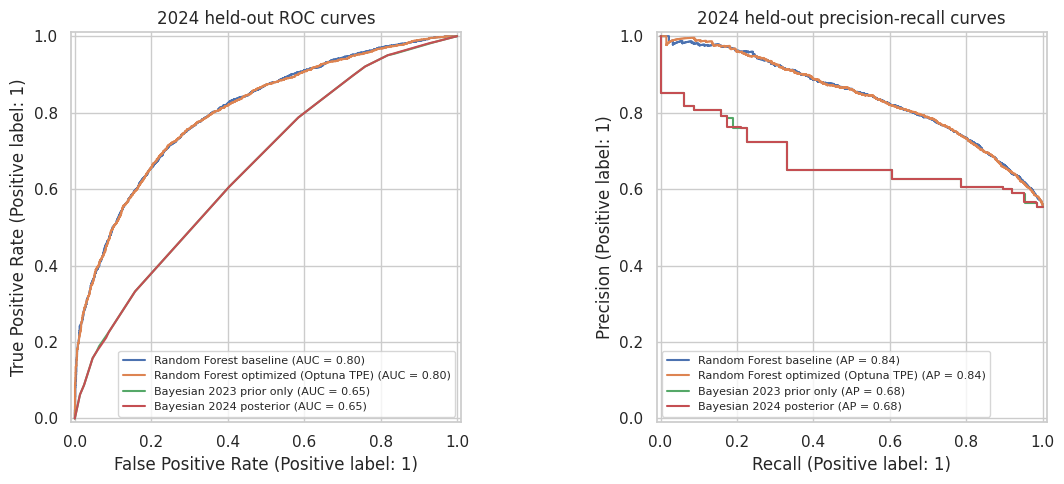

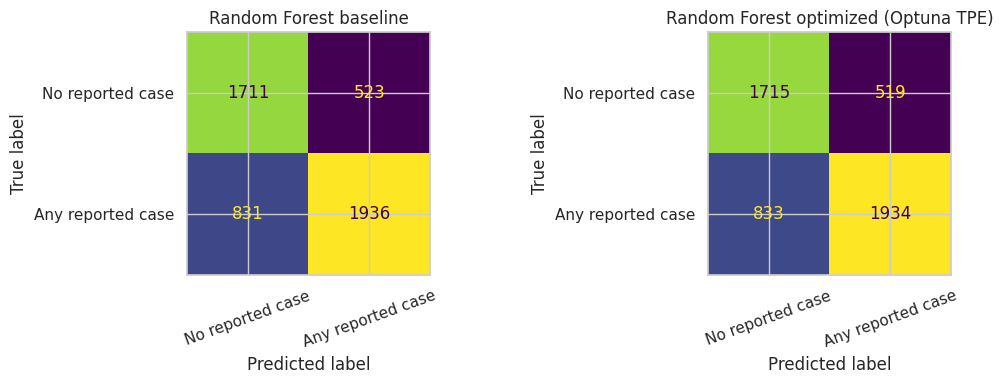

Best ROC-AUC on this single held-out test: Random Forest baseline
Reminder: higher ROC-AUC does not prove prior updating improved RF; the models are different.


In [12]:
predictions = {
    'Random Forest baseline': rf_baseline_probs,
    'Random Forest optimized (Optuna TPE)': rf_optimized_probs,
    'Bayesian 2023 prior only': bayes_prior_probs,
    'Bayesian 2024 posterior': bayes_posterior_probs,
}

def evaluate(name, probabilities):
    p = np.clip(np.asarray(probabilities, dtype=float), 1e-6, 1-1e-6)
    yhat = (p >= 0.5).astype(int)
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, yhat),
        'Precision': precision_score(y_test, yhat, zero_division=0),
        'Recall': recall_score(y_test, yhat, zero_division=0),
        'F1': f1_score(y_test, yhat, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, p),
        'PR-AUC': average_precision_score(y_test, p),
        'Brier (lower better)': brier_score_loss(y_test, p),
        'Log Loss (lower better)': log_loss(y_test, p),
    }

results = pd.DataFrame([evaluate(name,p) for name,p in predictions.items()]).set_index('Model')
display(results.round(4))

fig, (ax1,ax2) = plt.subplots(1,2,figsize=(12,5))
for name, prob in predictions.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=ax1)
    PrecisionRecallDisplay.from_predictions(y_test, prob, name=name, ax=ax2)
ax1.set_title('2024 held-out ROC curves')
ax2.set_title('2024 held-out precision-recall curves')
ax1.legend(fontsize=8); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1,2,figsize=(11,4))
for ax,(name, prob) in zip(axes, list(predictions.items())[:2]):
    ConfusionMatrixDisplay.from_predictions(y_test, (prob>=0.5).astype(int),
                                            display_labels=['No reported case','Any reported case'],
                                            ax=ax, colorbar=False)
    ax.set_title(name)
    ax.tick_params(axis='x', labelrotation=20)
plt.tight_layout(); plt.show()

best_auc = results['ROC-AUC'].idxmax()
print('Best ROC-AUC on this single held-out test:', best_auc)
print('Reminder: higher ROC-AUC does not prove prior updating improved RF; the models are different.')

## 10. Optional MCMC convergence trace with **PyMC**

Because the above Beta-Binomial model is conjugate, its posterior is available **exactly**, with no sampling needed. For the assignment's **parameter convergence plot**, we optionally reproduce the posterior of the five best-supported groups using PyMC's MCMC sampler and ArviZ trace plots. This **does not change** the test predictions, which were obtained from the exact posterior.

Check `r_hat` near 1 and effective sample size (`ess_bulk`) before trusting Monte Carlo summaries. If PyMC is unavailable or compilation is expensive, set `RUN_PYMC_TRACE = False`; the exact Bayesian updating section still works.

Output()

MCMC diagnostics (posterior risk parameters):


,mean,sd,ess_bulk,r_hat
risk[238|2],0.607,0.007,1060.0,1.0
risk[238|21],0.572,0.009,1240.0,1.0
risk[236|2],0.515,0.010,1336.0,1.0
risk[237|2],0.636,0.011,1325.0,1.0
risk[238|1],0.277,0.014,1160.0,1.0


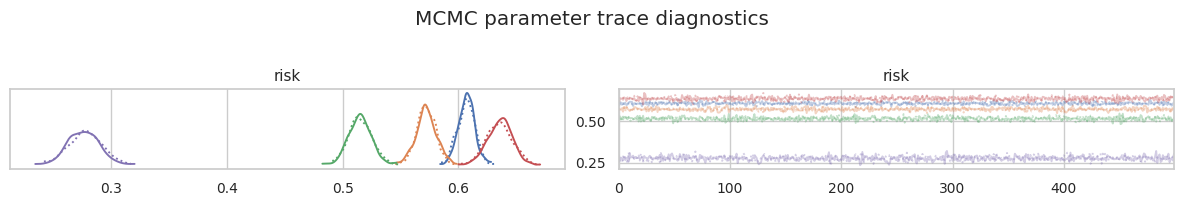

In [13]:
if RUN_PYMC_TRACE:
    import pymc as pm
    import arviz as az
    subset = post.query('n24_train >= 5').sort_values('n24_train',ascending=False).head(5).copy()
    if len(subset) == 0:
        print('No group has enough training examples for illustrative MCMC traces.')
    else:
        cohort_names = subset.cohort.tolist()
        with pm.Model(coords={'cohort': cohort_names}) as beta_binom:
            risk = pm.Beta('risk', alpha=subset.alpha0.to_numpy(dtype=float),
                           beta=subset.beta0.to_numpy(dtype=float), dims='cohort')
            cases = pm.Binomial('observed_cases', n=subset.n24_train.to_numpy(dtype=int),
                                p=risk, observed=subset.s24_train.to_numpy(dtype=int), dims='cohort')
            posterior_trace = pm.sample(draws=500, tune=500, chains=2, cores=2,
                                        random_seed=SEED, target_accept=0.9,
                                        return_inferencedata=True)
        print('MCMC diagnostics (posterior risk parameters):')
        display(az.summary(posterior_trace, var_names=['risk'])[['mean','sd','ess_bulk','r_hat']])
        az.plot_trace(posterior_trace, var_names=['risk'], compact=True)
        plt.suptitle('MCMC parameter trace diagnostics', y=1.02)
        plt.tight_layout(); plt.show()

## 11. Final Model Performance and Bayesian Posterior Results

This section presents the performance metrics for the Random Forest and Bayesian models, followed by the estimated prior and posterior probabilities for construction industry cohorts.

In [14]:
from IPython.display import display, Markdown

# Display model performance results
display(Markdown("### Random Forest and Bayesian Model Results"))
display(results.round(6))

# Display Bayesian posterior results
display(Markdown("### Bayesian Cohort Posterior Results"))
display(
    post[
        ['cohort', 'n23', 'n24_train', 'prior_mean',
         'posterior_mean', 'ci_low', 'ci_high']
    ].round(6)
)

### Random Forest and Bayesian Model Results

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier (lower better),Log Loss (lower better)
Model,,,,,,,,
Random Forest baseline,0.729254,0.787312,0.699675,0.740911,0.803420,0.841183,0.181075,0.536547
Random Forest optimized (Optuna TPE),0.729654,0.788422,0.698952,0.740996,0.802374,0.841373,0.181508,0.537976
Bayesian 2023 prior only,0.618076,0.604487,0.895916,0.721899,0.654362,0.677210,0.227113,0.645159
Bayesian 2024 posterior,0.616877,0.600283,0.920492,0.726676,0.654358,0.676913,0.227468,0.646091


### Bayesian Cohort Posterior Results

,cohort,n23,n24_train,prior_mean,posterior_mean,ci_low,ci_high
0,236|1,1401,493,0.204968,0.180112,0.148455,0.214078
1,236|2,4036,2153,0.511691,0.515503,0.494542,0.536438
2,236|21,2056,839,0.433956,0.443039,0.410200,0.476125
3,236|22,439,197,0.650245,0.645449,0.582488,0.706003
4,236|3,486,261,0.814624,0.826171,0.780814,0.867312
5,237|1,954,365,0.258289,0.237444,0.196928,0.280465
6,237|2,3619,1992,0.613657,0.635690,0.614606,0.656521
7,237|21,1865,847,0.482979,0.506775,0.473736,0.539785
8,237|22,637,321,0.712940,0.730352,0.682927,0.775304
9,237|3,1230,708,0.650043,0.675407,0.641258,0.708659


## 12. Results, Discussion, and Research Limitations

### 12.1 Model Performance and Comparative Analysis

The study evaluated four predictive approaches using a held-out test dataset of 5,001 construction establishments. The models included a baseline Random Forest classifier, an optimized Random Forest classifier using Optuna, a Bayesian model based on historical 2023 prior probabilities, and a Bayesian model incorporating posterior updates from 2024 training observations.

The baseline Random Forest achieved an accuracy of **72.93%** and a ROC-AUC of **0.8034**, demonstrating the strongest overall ability to distinguish between establishments that reported at least one recordable injury or illness and those that did not.

The optimized Random Forest achieved a slightly higher accuracy of **72.97%**, representing an improvement of approximately 0.04 percentage points. However, its ROC-AUC decreased marginally to **0.8024**. This suggests that Bayesian hyperparameter optimization did not produce a meaningful improvement in overall discrimination on the held-out test dataset.

The Bayesian prior-only model achieved an accuracy of **61.81%** and a ROC-AUC of **0.6544**. After incorporating 2024 training observations through Bayesian updating, the posterior model achieved an accuracy of **61.69%**, while ROC-AUC remained approximately **0.6544**.

Although the Bayesian posterior model did not improve overall accuracy or ROC-AUC, its recall increased from **89.59% to 92.05%**, and its F1-score increased from **0.7219 to 0.7267**. This indicates a change in the model's classification behavior, with more positive cases being identified, although at the expense of other performance measures.

The baseline Random Forest also achieved a lower Brier score (**0.1811**) than the Bayesian posterior model (**0.2275**), indicating better probabilistic prediction performance according to this metric.

These findings demonstrate that Random Forest performed better for this particular dataset and experimental configuration. However, the results do not establish that Random Forest is universally superior to Bayesian methods.

### 12.2 Interpretation of Random Forest and Bayesian Performance

A possible explanation for the performance difference is the amount of predictive information available to each model.

The Random Forest models incorporated multiple historical predictors, including establishment size, employee count, total hours worked, previous injury or illness reporting, historical case counts, historical injury rates, geographic location, and construction industry classifications.

In contrast, the Bayesian Beta-Binomial model estimated injury or illness reporting probabilities using groups defined by construction subsector and establishment size. This simpler approach did not incorporate the complete set of predictors available to Random Forest.

Consequently, the comparison evaluates two different modeling strategies with different levels of information rather than isolating the effects of the algorithms themselves.

Random Forest can capture nonlinear relationships and interactions among predictors, which may help explain its stronger performance. The Bayesian cohort model provides a simpler probabilistic representation that allows historical probabilities to be updated as additional observations become available.

The limited change between Bayesian prior and posterior performance suggests that updating cohort-level probabilities did not substantially improve discrimination on the test dataset. Nevertheless, the Bayesian approach remains useful for representing uncertainty and examining how risk estimates change as additional observations are incorporated.

The PyMC analysis also demonstrated satisfactory MCMC convergence diagnostics for the five evaluated cohorts, with reported R-hat values of approximately 1.00. These diagnostics support the convergence of the sampling procedure but do not independently establish predictive accuracy.

### 12.3 Establishment Matching and Data Quality

An important methodological challenge involved identifying construction establishments that appeared in both the 2023 and 2024 OSHA datasets.

The preprocessing stage identified **23,764 establishments** with matching establishment identifiers across the two reporting years. After excluding **104 records** with inconsistencies in state or three-digit NAICS subsector, the final matched dataset contained **23,660 establishments**.

To further assess matching reliability, normalized establishment names were compared across both years. Approximately **97.9%** of retained records had identical normalized establishment names.

The remaining approximately **2.1%** contained differences that may reflect changes in business names, spelling variations, administrative updates, or potentially incorrect record matches.

Matching identifiers across reporting years does not guarantee that every record represents the same operating establishment. Incorrect matches could introduce errors into historical predictors or outcome labels.

Although the matching procedures improve data consistency, manual verification of ambiguous records or additional matching criteria would strengthen the reliability of future research.

Furthermore, restricting the analysis to establishments appearing in both reporting years introduces potential selection bias. Establishments that closed, changed reporting identifiers, or did not submit data in both years may be excluded. Therefore, the resulting sample should not be interpreted as representative of the entire U.S. construction industry.

### 12.4 Study Limitations

Several limitations should be considered when interpreting the findings.

**First, dataset representativeness:** OSHA's Injury Tracking Application contains records from establishments subject to applicable electronic reporting requirements. It does not represent every construction establishment in the United States. The findings therefore apply primarily to the retained reporting-establishment cohort.

**Second, unequal model complexity:** The Random Forest models utilized a broader set of establishment characteristics than the Bayesian cohort models. This limits the conclusions that can be drawn about the relative superiority of the modeling techniques.

**Third, reporting-related uncertainty:** The outcome reflects whether an establishment reported at least one OSHA-recordable injury or illness. Differences in reporting practices, establishment size, and administrative procedures may influence the observed outcomes. A reported-case classification should not be interpreted as a complete measure of workplace safety.

**Fourth, limited historical information:** The analysis used 2023 establishment information to predict 2024 outcomes. A longer historical period would allow examination of changes across multiple years and provide stronger evidence about temporal generalization.

**Fifth, predictive rather than causal analysis:** The models identify statistical relationships between historical characteristics and subsequent reporting outcomes. They do not demonstrate that particular establishment characteristics directly cause workplace injuries or illnesses.

**Finally, limited external validation:** The models were evaluated on a single held-out test split from the matched dataset. Additional temporal validation, independent datasets, and uncertainty estimates would be necessary to assess the stability and generalizability of the findings.

### 12.5 Future Research Directions

Future research could extend this study in several ways.

**Expanded historical analysis:** Incorporating additional years of OSHA data could enable longitudinal modeling of injury reporting patterns and improve understanding of how establishment-level risks change over time.

**Comparable Bayesian classification models:** A Bayesian logistic regression or hierarchical Bayesian model incorporating the same historical predictors as Random Forest would provide a more balanced comparison between machine learning and Bayesian inference.

**Improved establishment matching:** Additional validation using employer names, addresses, and other available identifiers could improve confidence in year-over-year record linkage.

**Probability calibration:** Future experiments could investigate whether calibration methods improve the reliability of predicted probabilities, particularly when models are intended to support risk-based decision-making.

**Additional construction variables:** Integrating publicly available information about weather conditions, regional economic activity, and construction employment trends could help evaluate whether broader industry conditions contribute additional predictive information.

**Multi-year external validation:** Training models on earlier reporting years and evaluating them on later years would provide stronger evidence of real-world predictive performance.

These extensions could support the development of more comprehensive construction safety risk assessment methods.

### 12.6 Conclusion

This study demonstrated the feasibility of applying Random Forest, Bayesian Optimization, and Bayesian updating to publicly available U.S. construction industry safety data.

The baseline Random Forest achieved the strongest ROC-AUC of **0.8034**, while the optimized Random Forest produced a marginal improvement in classification accuracy. The Bayesian models provided interpretable cohort-level probability estimates but demonstrated weaker predictive discrimination in this experimental configuration.

The findings suggest that historical establishment characteristics contain useful predictive information about subsequent OSHA injury or illness reporting. However, model performance depends on the available predictors, the modeling strategy, and the quality of the underlying data.

Overall, the project demonstrates the value of combining machine learning evaluation with probabilistic reasoning while highlighting the importance of reliable data preparation, fair model comparisons, and careful interpretation of predictive results.